In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import pandas as pd

# Load the dataset
df = pd.read_excel('/content/Real estate valuation data set.xlsx')

# Display first 5 rows
df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


In [3]:
# Check number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check data types
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (414, 8)

Column Names:
Index(['No', 'X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude',
       'Y house price of unit area'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,207.500000,2013.148953,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,119.655756,0.281995,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,1.000000,2012.666667,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,104.250000,2012.916667,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,207.500000,2013.166667,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,310.750000,2013.416667,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,414.000000,2013.583333,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


In [4]:
# Select Input Feature (X)
X = df[["X3 distance to the nearest MRT station"]]

# Select Target Feature (Y)
Y = df["Y house price of unit area"]

# Display selected features
print("Input Feature (X):")
display(X.head())

print("Target Feature (Y):")
display(Y.head())

print("Input Shape:", X.shape)
print("Target Shape:", Y.shape)

Input Feature (X):


,X3 distance to the nearest MRT station
0,84.87882
1,306.59470
2,561.98450
3,561.98450
4,390.56840


Target Feature (Y):


,Y house price of unit area
0,37.9
1,42.2
2,47.3
3,54.8
4,43.1


Input Shape: (414, 1)
Target Shape: (414,)


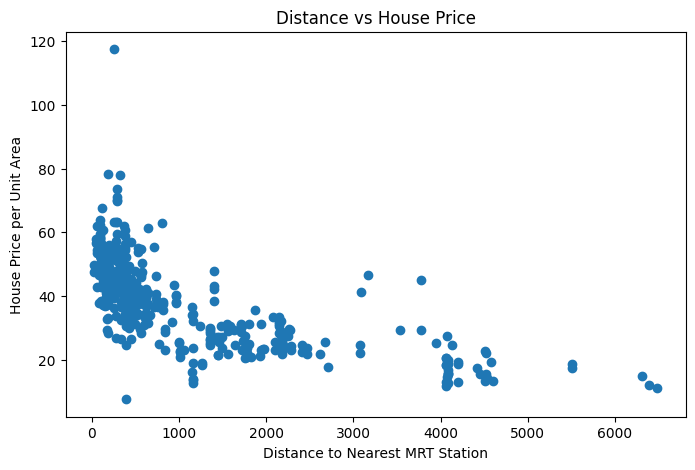

In [5]:
plt.figure(figsize=(8, 5))

plt.scatter(X, Y)

plt.title("Distance vs House Price")
plt.xlabel("Distance to Nearest MRT Station")
plt.ylabel("House Price per Unit Area")

plt.show()

In [6]:
# Split the dataset into training and testing data

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 331
Testing Records: 83


In [7]:
# Create Linear Regression Model

model = LinearRegression()

# Train the model
model.fit(X_train, Y_train)

# Display coefficient and intercept
print("Coefficient:", model.coef_[0])

print("Intercept:", model.intercept_)

Coefficient: -0.00740951293493293
Intercept: 46.24269004533653


In [8]:
# Predict house prices using test data

Y_pred = model.predict(X_test)

# Compare actual and predicted values

comparison = pd.DataFrame({
    "Actual Price": Y_test.values,
    "Predicted Price": Y_pred
})

display(comparison.head(10))

,Actual Price,Predicted Price
0,45.1,44.808323
1,42.3,42.595496
2,52.2,44.212377
3,37.3,44.982118
4,22.8,30.051956
5,36.3,43.097024
6,53.0,44.098934
7,51.4,44.098934
8,16.1,37.748950
9,59.0,45.572455


In [9]:
# Calculate MAE
mae = mean_absolute_error(Y_test, Y_pred)

# Calculate MSE
mse = mean_squared_error(Y_test, Y_pred)

# Calculate RMSE
rmse = np.sqrt(mse)

# Calculate R2 Score
r2 = r2_score(Y_test, Y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 6.920972703573579
MSE: 77.34399178518461
RMSE: 8.794543295998071
R2 Score: 0.538959766501977


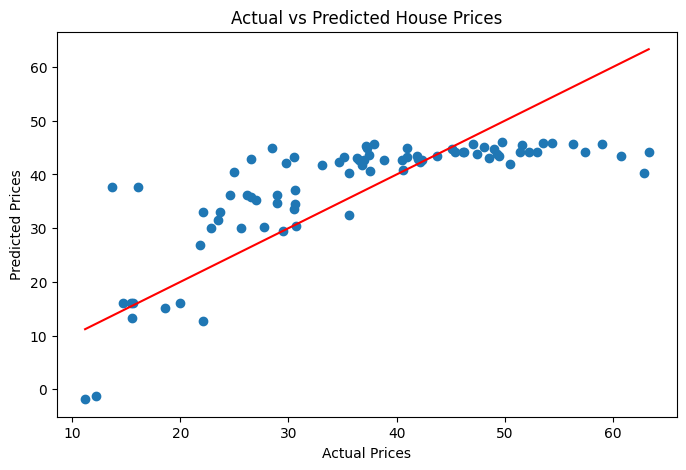

In [10]:
plt.figure(figsize=(8,5))

plt.scatter(Y_test, Y_pred)

# Reference line for perfect predictions
plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    color="red"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")

plt.show()

In [11]:
# New house distance
new_house = pd.DataFrame({
    "X3 distance to the nearest MRT station": [1000]
})

# Predict house price
new_prediction = model.predict(new_house)

print("New House Distance: 1000 meters")

print("Predicted House Price per Unit Area:",
      new_prediction[0])

New House Distance: 1000 meters
Predicted House Price per Unit Area: 38.833177110403604


In [12]:
# Split dataset into training and testing data

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 331
Testing Records: 83


In [13]:
# Create Linear Regression Model

model = LinearRegression()

# Train the model
model.fit(X_train, Y_train)

# Display coefficient and intercept
print("Coefficient:", model.coef_[0])

print("Intercept:", model.intercept_)

Coefficient: -0.00740951293493293
Intercept: 46.24269004533653


In [14]:
# Predict house prices using testing data

Y_pred = model.predict(X_test)

# Create comparison table

comparison = pd.DataFrame({
    "Actual Price": Y_test.values,
    "Predicted Price": Y_pred
})

# Display first 10 predictions

display(comparison.head(10))

,Actual Price,Predicted Price
0,45.1,44.808323
1,42.3,42.595496
2,52.2,44.212377
3,37.3,44.982118
4,22.8,30.051956
5,36.3,43.097024
6,53.0,44.098934
7,51.4,44.098934
8,16.1,37.748950
9,59.0,45.572455


In [15]:
# Calculate Mean Absolute Error
mae = mean_absolute_error(Y_test, Y_pred)

# Calculate Mean Squared Error
mse = mean_squared_error(Y_test, Y_pred)

# Calculate Root Mean Squared Error
rmse = np.sqrt(mse)

# Calculate R2 Score
r2 = r2_score(Y_test, Y_pred)

# Display results
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 6.920972703573579
MSE: 77.34399178518461
RMSE: 8.794543295998071
R2 Score: 0.538959766501977


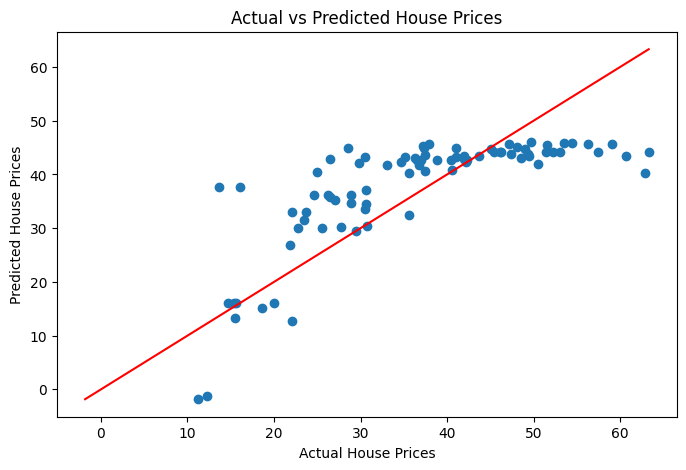

In [16]:
plt.figure(figsize=(8,5))

plt.scatter(Y_test, Y_pred)

# Perfect prediction reference line
minimum = min(Y_test.min(), Y_pred.min())
maximum = max(Y_test.max(), Y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.show()

In [17]:
# Give a new house distance
new_house = pd.DataFrame({
    "X3 distance to the nearest MRT station": [1000]
})

# Predict house price
new_prediction = model.predict(new_house)

print("Distance:", 1000, "meters")

print("Predicted House Price per Unit Area:",
      new_prediction[0])

Distance: 1000 meters
Predicted House Price per Unit Area: 38.833177110403604


### Conclusion

In this activity, I developed a House Price Prediction model using Linear Regression. I used the Real Estate Valuation dataset containing 414 records. Distance to the nearest MRT station was selected as the input feature and house price per unit area was selected as the target variable.

The dataset was divided into 80% training data and 20% testing data. The model was evaluated using MAE, MSE and R² score.

Finally, I tested the model with a new distance of 1000 meters and obtained a predicted price of 38.8333 (10,000 New Taiwan Dollars per Ping).

This activity helped me understand Linear Regression, model training, prediction and evaluation. The model has a limitation because it uses only one input feature, while actual house prices depend on several factors.

### Model Evaluation

The Linear Regression model was evaluated using four performance metrics.

- MAE = 6.92
- MSE = 77.34
- RMSE = 8.79
- R² Score = 0.539

The R² score indicates that the model explains approximately 53.9% of the variation in house prices. The model provides a moderate prediction performance.